# 手游 A/B 实验分析：关卡门槛该放在第 30 关还是第 40 关？

**背景：** Cookie Cats 是一款消除类手游。玩家通关到某一关时会遇到"门槛"（gate），必须等待一段时间或付费才能继续。产品团队想知道：**把第一个门槛从第 30 关推迟到第 40 关，会不会影响玩家留存？**

**实验设计：** 新安装游戏的玩家被随机分到两组：

| 组别 | 门槛位置 | 角色 |
|---|---|---|
| gate_30 | 第 30 关 | 对照组（现状） |
| gate_40 | 第 40 关 | 实验组（新方案） |

**指标：**

| 类型 | 指标 | 说明 |
|---|---|---|
| 核心指标 | 七日留存 `retention_7` | 安装 7 天后是否还回来玩，反映中期黏性，是决策依据 |
| 次要指标 | 次日留存 `retention_1` | 安装 1 天后是否回来玩 |
| 护栏指标 | 游戏局数 `sum_gamerounds` | 安装后 14 天内玩了多少局，确保新方案没有损害活跃度 |

**分析流程：** 数据检查 → 分流检查 → 统计功效 → 核心指标检验 → 自助法验证 → 护栏指标 → 多重检验校正 → 结论与建议

**数据来源：** Kaggle "Mobile Games A/B Testing – Cookie Cats"（原始来自 DataCamp），90,189 名玩家。

In [14]:
# 在 Google Colab 上运行时先执行这一格；在自己电脑上运行会自动跳过
import os, sys, subprocess, zipfile
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    root = "/content/drive/MyDrive/mobile-game-ab-test"
    if not os.path.exists(root):
        zipfile.ZipFile("/content/drive/MyDrive/mobile-game-ab-test.zip").extractall("/content/drive/MyDrive")
    os.chdir(root + "/notebooks")
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True, check=True)
    import matplotlib.font_manager as fm
    for f in fm.findSystemFonts():
        if "NotoSansCJK" in f:
            fm.fontManager.addfont(f)
    print("Colab 环境准备完成，当前目录：", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab 环境准备完成，当前目录： /content/drive/MyDrive/mobile-game-ab-test/notebooks


In [15]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path("..").resolve()
DATA = ROOT / "data" / "cookie_cats.csv"
FIG_DIR, RES_DIR = ROOT / "figures", ROOT / "results"
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

warnings.filterwarnings("ignore", message="Glyph .* missing from font")
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti TC", "Arial Unicode MS", "Microsoft YaHei",
                                   "SimHei", "Noto Sans CJK SC", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

BLUE, ORANGE, GREY = "#3B6FB6", "#E07B39", "#9AA5B1"
COLORS = {"gate_30": BLUE, "gate_40": ORANGE}
ALPHA = 0.05
rng = np.random.default_rng(42)
summary = {}


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)


df = pd.read_csv(DATA)
print(f"玩家数：{len(df):,}")
df.head()

玩家数：90,189


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. 数据检查

In [16]:
check = pd.Series({
    "玩家数": len(df),
    "重复的玩家编号": int(df["userid"].duplicated().sum()),
    "缺失值": int(df.isna().sum().sum()),
    "组别取值": ", ".join(sorted(df["version"].unique())),
    "0 局玩家占比": f"{(df['sum_gamerounds'] == 0).mean():.2%}",
    "游戏局数中位数": int(df["sum_gamerounds"].median()),
    "游戏局数最大值": int(df["sum_gamerounds"].max()),
})
check.to_frame("值")

,值
玩家数,90189
重复的玩家编号,0
缺失值,0
组别取值,"gate_30, gate_40"
0 局玩家占比,4.43%
游戏局数中位数,16
游戏局数最大值,49854


游戏局数最多的 3 名玩家：


,userid,version,sum_gamerounds
57702,6390605,gate_30,49854
7912,871500,gate_30,2961
29417,3271615,gate_40,2640


最多的一名玩家 14 天玩了 49,854 局（每天约 3,561 局），是第二名（2,961 局）的 17 倍，判断为异常数据（可能是测试账号或脚本）。


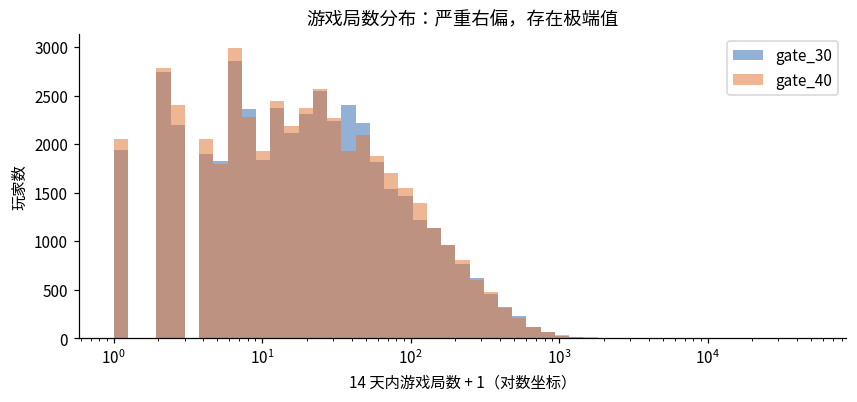

In [17]:
# 游戏局数严重右偏：用对数坐标看分布，并找出极端值
top = df.nlargest(3, "sum_gamerounds")[["userid", "version", "sum_gamerounds"]]
print("游戏局数最多的 3 名玩家：")
display(top)
second = int(df["sum_gamerounds"].nlargest(2).iloc[1])
print(f"最多的一名玩家 14 天玩了 {df['sum_gamerounds'].max():,} 局（每天约 {df['sum_gamerounds'].max() / 14:,.0f} 局），"
      f"是第二名（{second:,} 局）的 {df['sum_gamerounds'].max() / second:.0f} 倍，判断为异常数据（可能是测试账号或脚本）。")

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(0, np.log10(df["sum_gamerounds"].max() + 1), 50)
for v, g in df.groupby("version"):
    ax.hist(g["sum_gamerounds"] + 1, bins=bins, alpha=0.55, color=COLORS[v], label=v)
ax.set_xscale("log")
ax.set(xlabel="14 天内游戏局数 + 1（对数坐标）", ylabel="玩家数", title="游戏局数分布：严重右偏，存在极端值")
ax.legend()
save_fig(fig, "01_game_rounds_distribution")

**处理方式：**
- 留存指标不受局数极端值影响，**保留全部玩家**
- 护栏指标（游戏局数）的均值会被极端值严重拉高，所以**剔除这一名异常玩家**，并同时用对极端值不敏感的中位数和非参数检验

In [18]:
outlier_ids = df.loc[df["sum_gamerounds"] == df["sum_gamerounds"].max(), "userid"].tolist()
df_rounds = df[~df["userid"].isin(outlier_ids)]
print(f"护栏指标分析剔除 {len(outlier_ids)} 名异常玩家，剩余 {len(df_rounds):,} 名")

护栏指标分析剔除 1 名异常玩家，剩余 90,188 名


## 2. 分流检查（样本比例不匹配检验）

做任何结论之前，先确认**随机分组本身没出问题**。如果设计是 50:50 分流，实际人数却明显偏离，说明分流或数据记录可能有缺陷，实验结果就不可信。这一步在业界叫"样本比例不匹配检验"（Sample Ratio Mismatch），用卡方拟合优度检验。

In [19]:
counts = df["version"].value_counts().reindex(["gate_30", "gate_40"])
expected = [len(df) / 2] * 2
chi2_srm, p_srm = stats.chisquare(counts, expected)
srm = pd.DataFrame({"实际人数": counts, "占比": counts / len(df), "预期人数（50:50）": expected})
display(srm)
print(f"卡方值 = {chi2_srm:.2f}，P 值 = {p_srm:.4f}")
if p_srm < 0.01:
    print("⚠️ P 值小于 0.01，两组人数偏离 50:50 的程度超出随机波动范围，存在样本比例不匹配的迹象。"
          "实际工作中应先排查分流和埋点，再使用实验结论；这里继续分析，但在结论中标注这一风险。")
else:
    print("分流比例正常，没有发现样本比例不匹配。")
summary["分流检查"] = {"gate_30人数": int(counts["gate_30"]), "gate_40人数": int(counts["gate_40"]),
                    "卡方值": round(float(chi2_srm), 2), "P值": round(float(p_srm), 4)}

,实际人数,占比,预期人数（50:50）
version,,,
gate_30,44700,0.4956,"45,094.5000"
gate_40,45489,0.5044,"45,094.5000"


卡方值 = 6.90，P 值 = 0.0086
⚠️ P 值小于 0.01，两组人数偏离 50:50 的程度超出随机波动范围，存在样本比例不匹配的迹象。实际工作中应先排查分流和埋点，再使用实验结论；这里继续分析，但在结论中标注这一风险。


## 3. 统计功效：这个样本量能检测出多小的差异？

实验开始前就应该估算样本量。这里倒过来计算：在显著性水平 5%、统计功效 80% 的条件下，
1. 要检测出 **1 个百分点**的七日留存差异，每组需要多少玩家？
2. 用实际的样本量，**最小可检测差异**是多少？

> 实验结束后再算"事后统计功效"没有意义（它完全由 P 值决定），所以这里只做事前的样本量估算和最小可检测差异。

In [20]:
def sample_size_two_prop(p1, p2, alpha=ALPHA, power=0.8):
    # 两样本比例检验的每组样本量（双侧检验）
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    p_bar = (p1 + p2) / 2
    num = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2
    return int(np.ceil(num / (p1 - p2) ** 2))


def mde_two_prop(p, n_per_group, alpha=ALPHA, power=0.8):
    # 给定每组样本量时的最小可检测差异（绝对值）
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p * (1 - p) / n_per_group)


n_min = int(counts.min())
rows = []
for metric in ["retention_1", "retention_7"]:
    base = df.loc[df["version"] == "gate_30", metric].mean()
    rows.append({"指标": metric, "对照组基线": base,
                 "检测 1 个百分点差异所需每组人数": sample_size_two_prop(base, base - 0.01),
                 "实际每组人数（较少的一组）": n_min,
                 "最小可检测差异（百分点）": mde_two_prop(base, n_min) * 100})
power_df = pd.DataFrame(rows).set_index("指标")
summary["统计功效"] = {k: {"所需每组人数": int(v["检测 1 个百分点差异所需每组人数"]),
                       "最小可检测差异_百分点": round(float(v["最小可检测差异（百分点）"]), 2)}
                   for k, v in power_df.iterrows()}
power_df

,对照组基线,检测 1 个百分点差异所需每组人数,实际每组人数（较少的一组）,最小可检测差异（百分点）
指标,,,,
retention_1,0.4482,38737,44700,0.9319
retention_7,0.1902,23688,44700,0.7355


## 4. 核心指标检验：两样本比例 Z 检验

对次日留存和七日留存分别检验：H₀ 为两组留存率相同，H₁ 为不同（双侧）。

In [21]:
def two_prop_test(k1, n1, k2, n2, alpha=ALPHA):
    # 返回实验组减对照组的差值、置信区间、相对变化、Z 值和 P 值
    p1, p2 = k1 / n1, k2 / n2
    p_pool = (k1 + k2) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    zc = stats.norm.ppf(1 - alpha / 2)
    return {"对照组 gate_30": p1, "实验组 gate_40": p2, "差值（百分点）": (p2 - p1) * 100,
            "95%置信区间下限": (p2 - p1 - zc * se) * 100, "95%置信区间上限": (p2 - p1 + zc * se) * 100,
            "相对变化": (p2 - p1) / p1, "Z": z, "P值": p_value}


g = df.groupby("version")
tests = {}
for metric in ["retention_1", "retention_7"]:
    k, n = g[metric].sum(), g[metric].size()
    tests[metric] = two_prop_test(k["gate_30"], n["gate_30"], k["gate_40"], n["gate_40"])
test_df = pd.DataFrame(tests).T
test_df

,对照组 gate_30,实验组 gate_40,差值（百分点）,95%置信区间下限,95%置信区间上限,相对变化,Z,P值
retention_1,0.4482,0.4423,-0.5905,-1.2392,0.0582,-0.0132,-1.7841,0.0744
retention_7,0.1902,0.1820,-0.8201,-1.3282,-0.3121,-0.0431,-3.1644,0.0016


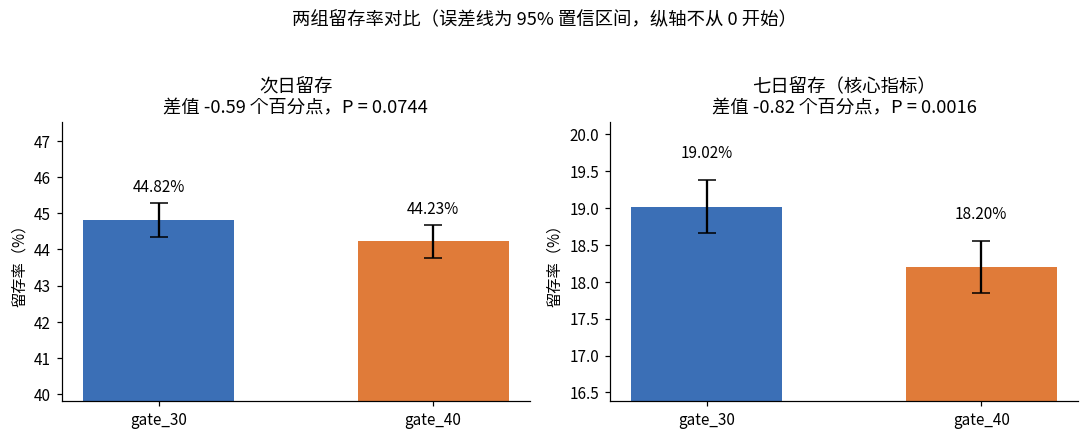

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, metric, title in zip(axes, ["retention_1", "retention_7"], ["次日留存", "七日留存（核心指标）"]):
    rates = g[metric].mean()
    ses = np.sqrt(rates * (1 - rates) / g[metric].size())
    ax.bar(rates.index, rates * 100, yerr=1.96 * ses * 100, capsize=6,
           color=[COLORS[v] for v in rates.index], width=0.55)
    for i, r in enumerate(rates):
        ax.text(i, r * 100 + 1.96 * ses.iloc[i] * 100 + 0.3, f"{r:.2%}", ha="center")
    lo = (rates.min() * 100) * 0.9
    ax.set_ylim(lo, rates.max() * 100 * 1.06)
    p = tests[metric]["P值"]
    ax.set_title(f"{title}\n差值 {tests[metric]['差值（百分点）']:+.2f} 个百分点，P = {p:.4f}")
    ax.set_ylabel("留存率（%）")
fig.suptitle("两组留存率对比（误差线为 95% 置信区间，纵轴不从 0 开始）", y=1.04)
fig.tight_layout()
save_fig(fig, "02_retention_comparison")

## 5. 自助法验证

Z 检验依赖正态近似。用**自助法**（Bootstrap）再验证一次：对两组分别有放回地重复抽样 10,000 次，得到留存率差值的分布，直接读出置信区间，以及"对照组留存更高"的概率。

> 对 0/1 变量，有放回抽样 n 次后的均值，等价于从参数为 (n, p̂) 的二项分布中抽一个数再除以 n，所以可以直接用二项分布抽样，速度快很多，结果完全等价。

,差值均值（百分点）,95%区间下限,95%区间上限,gate_30更好的概率
retention_1,0.5928,-0.0606,1.2522,0.9653
retention_7,0.8212,0.3074,1.3244,0.9990


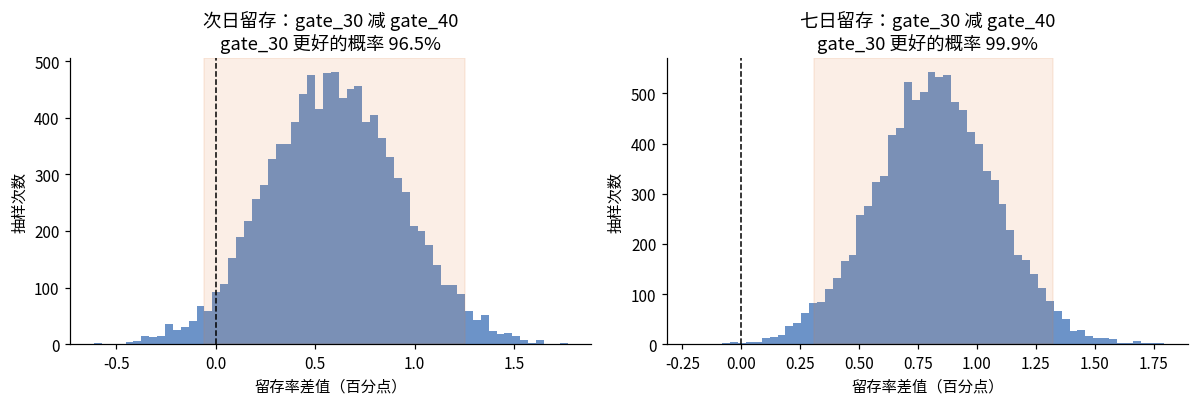

In [23]:
B = 10_000
boot = {}
for metric in ["retention_1", "retention_7"]:
    n, p = g[metric].size(), g[metric].mean()
    b30 = rng.binomial(n["gate_30"], p["gate_30"], B) / n["gate_30"]
    b40 = rng.binomial(n["gate_40"], p["gate_40"], B) / n["gate_40"]
    boot[metric] = (b30 - b40) * 100        # 对照组减实验组，正数表示 gate_30 更好

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
boot_rows = {}
for ax, metric, title in zip(axes, ["retention_1", "retention_7"], ["次日留存", "七日留存"]):
    d = boot[metric]
    lo, hi = np.percentile(d, [2.5, 97.5])
    prob = (d > 0).mean()
    boot_rows[metric] = {"差值均值（百分点）": d.mean(), "95%区间下限": lo, "95%区间上限": hi,
                         "gate_30更好的概率": prob}
    ax.hist(d, bins=60, color=BLUE, alpha=0.75)
    ax.axvline(0, color="black", ls="--", lw=1)
    ax.axvspan(lo, hi, color=ORANGE, alpha=0.12)
    ax.set(title=f"{title}：gate_30 减 gate_40\ngate_30 更好的概率 {prob:.1%}",
           xlabel="留存率差值（百分点）", ylabel="抽样次数")
fig.tight_layout()
save_fig(fig, "03_bootstrap_difference")
boot_df = pd.DataFrame(boot_rows).T
boot_df

## 6. 护栏指标：游戏局数有没有受损？

游戏局数严重右偏，均值容易被少数重度玩家左右，所以同时看三个口径：
- **Mann-Whitney U 检验**（非参数，比较整体分布，不受极端值影响）
- **中位数**
- **均值的自助法置信区间**（已剔除异常玩家）

In [24]:
r30 = df_rounds.loc[df_rounds["version"] == "gate_30", "sum_gamerounds"].to_numpy()
r40 = df_rounds.loc[df_rounds["version"] == "gate_40", "sum_gamerounds"].to_numpy()
u_stat, p_mw = stats.mannwhitneyu(r40, r30, alternative="two-sided")

B_MEAN = 2_000
diffs = np.empty(B_MEAN)
for i in range(B_MEAN):
    diffs[i] = r40[rng.integers(0, len(r40), len(r40))].mean() - r30[rng.integers(0, len(r30), len(r30))].mean()
lo, hi = np.percentile(diffs, [2.5, 97.5])

guard = pd.Series({
    "gate_30 均值": r30.mean(), "gate_40 均值": r40.mean(),
    "均值差（gate_40 减 gate_30）": r40.mean() - r30.mean(),
    "均值差 95% 自助法区间下限": lo, "均值差 95% 自助法区间上限": hi,
    "gate_30 中位数": np.median(r30), "gate_40 中位数": np.median(r40),
    "Mann-Whitney U 检验 P 值": p_mw,
})
summary["护栏指标_游戏局数"] = {k: round(float(v), 4) for k, v in guard.items()}
guard.to_frame("值")

,值
gate_30 均值,51.3421
gate_40 均值,51.2988
均值差（gate_40 减 gate_30）,-0.0433
均值差 95% 自助法区间下限,-1.2938
均值差 95% 自助法区间上限,1.3714
gate_30 中位数,17.0000
gate_40 中位数,16.0000
Mann-Whitney U 检验 P 值,0.0509


## 7. 多重检验校正

同时检验了次日留存和七日留存两个指标，犯第一类错误的概率会上升。用 **Holm 校正**（比 Bonferroni 更不保守）调整 P 值，确认结论是否依然成立。

In [25]:
pvals = pd.Series({m: tests[m]["P值"] for m in ["retention_1", "retention_7"]}).sort_values()
m = len(pvals)
holm = pd.Series({name: min(1.0, p * (m - i)) for i, (name, p) in enumerate(pvals.items())})
holm = holm.cummax()     # 保证校正后的 P 值单调
mt = pd.DataFrame({"原始P值": pvals, "Holm校正后P值": holm, "校正后是否显著": holm < ALPHA})
mt

,原始P值,Holm校正后P值,校正后是否显著
retention_7,0.0016,0.0031,True
retention_1,0.0744,0.0744,False


In [26]:
summary["核心指标检验"] = {
    k: {"对照组": round(float(v["对照组 gate_30"]), 4), "实验组": round(float(v["实验组 gate_40"]), 4),
        "差值_百分点": round(float(v["差值（百分点）"]), 3),
        "置信区间_百分点": [round(float(v["95%置信区间下限"]), 3), round(float(v["95%置信区间上限"]), 3)],
        "相对变化": round(float(v["相对变化"]), 4), "P值": round(float(v["P值"]), 4),
        "Holm校正后P值": round(float(holm[k]), 4)}
    for k, v in tests.items()}
summary["自助法"] = {k: {"gate_30更好的概率": round(float(v["gate_30更好的概率"]), 4),
                      "区间_百分点": [round(float(v["95%区间下限"]), 3), round(float(v["95%区间上限"]), 3)]}
                  for k, v in boot_df.iterrows()}

r7, r1 = tests["retention_7"], tests["retention_1"]
print(f"七日留存：gate_40 比 gate_30 低 {abs(r7['差值（百分点）']):.2f} 个百分点（相对下降 {abs(r7['相对变化']):.1%}），"
      f"P = {r7['P值']:.4f}，Holm 校正后 P = {holm['retention_7']:.4f}，"
      f"自助法下 gate_30 更好的概率 {boot_df.loc['retention_7', 'gate_30更好的概率']:.1%}")
print(f"次日留存：差 {r1['差值（百分点）']:+.2f} 个百分点，P = {r1['P值']:.4f}，校正后 P = {holm['retention_1']:.4f}")
print(f"护栏指标：游戏局数 Mann-Whitney U 检验 P = {p_mw:.4f}")
print(f"分流检查：P = {p_srm:.4f}")

(RES_DIR / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("\n已写入 results/summary.json")

七日留存：gate_40 比 gate_30 低 0.82 个百分点（相对下降 4.3%），P = 0.0016，Holm 校正后 P = 0.0031，自助法下 gate_30 更好的概率 99.9%
次日留存：差 -0.59 个百分点，P = 0.0744，校正后 P = 0.0744
护栏指标：游戏局数 Mann-Whitney U 检验 P = 0.0509
分流检查：P = 0.0086

已写入 results/summary.json


## 8. 结论与建议

**结论：**
- 七日留存（核心指标）：gate_40 比 gate_30 低 0.82 个百分点（19.02% → 18.20%，相对下降 4.3%），P = 0.0016，Holm 校正后 P = 0.0031；自助法下 gate_30 更好的概率为 99.9%
- 次日留存：低 0.59 个百分点，P = 0.074，不显著
- 护栏指标：游戏局数两组均值几乎相同（51.34 对 51.30），Mann-Whitney U 检验 P = 0.051，没有显著差异
- 分流检查：两组人数偏离 50:50（P = 0.0086），存在样本比例不匹配的迹象

**建议：** 保留第 30 关门槛，不推迟到第 40 关。正式决策前先排查分流和埋点，确认样本比例偏差不影响结论。

**可能的解释：** 门槛强制玩家暂停，反而延长了游戏的新鲜感；门槛推迟后玩家一口气玩得更久，更快感到厌倦。

**局限：**
- 只有次日和七日留存，看不到长期留存和付费收入，门槛位置还会影响付费意愿
- 没有玩家的历史特征，无法做分层分析；也不能按游戏局数分层，因为局数本身受实验影响
- 分流比例的偏差需要先排查原因